=== Stable PINN for 1D Oldroyd-B Flow ===
Physical parameters: η_s=0.1, η_p=0.9, λ=0.1, L=1.0
Epoch    0, Loss: 10.000018, PDE: 0.000000, BC: 1.000002
Epoch  500, Loss: 0.771189, PDE: 0.595336, BC: 0.017585
Epoch 1000, Loss: 0.734434, PDE: 0.558233, BC: 0.017620
[Adaptive] Added points, total: 3200
Epoch 1500, Loss: 0.689529, PDE: 0.552029, BC: 0.013750
[Adaptive] Added points, total: 3250
Epoch 2000, Loss: 0.620249, PDE: 0.482028, BC: 0.013822
[Adaptive] Added points, total: 3255
Epoch 2500, Loss: 0.581260, PDE: 0.458602, BC: 0.012266
[Adaptive] Added points, total: 3285
Epoch 3000, Loss: 0.546331, PDE: 0.432688, BC: 0.011364
[Adaptive] Added points, total: 3285
Epoch 3500, Loss: 0.501109, PDE: 0.398384, BC: 0.010272
[Adaptive] Added points, total: 3285
Epoch 4000, Loss: 0.460241, PDE: 0.359677, BC: 0.010056
[Adaptive] Added points, total: 3285
Epoch 4500, Loss: 0.408573, PDE: 0.326859, BC: 0.008171
[Adaptive] Added points, total: 3301
Epoch 5000, Loss: 0.365632, PDE: 0.285661, BC: 0.

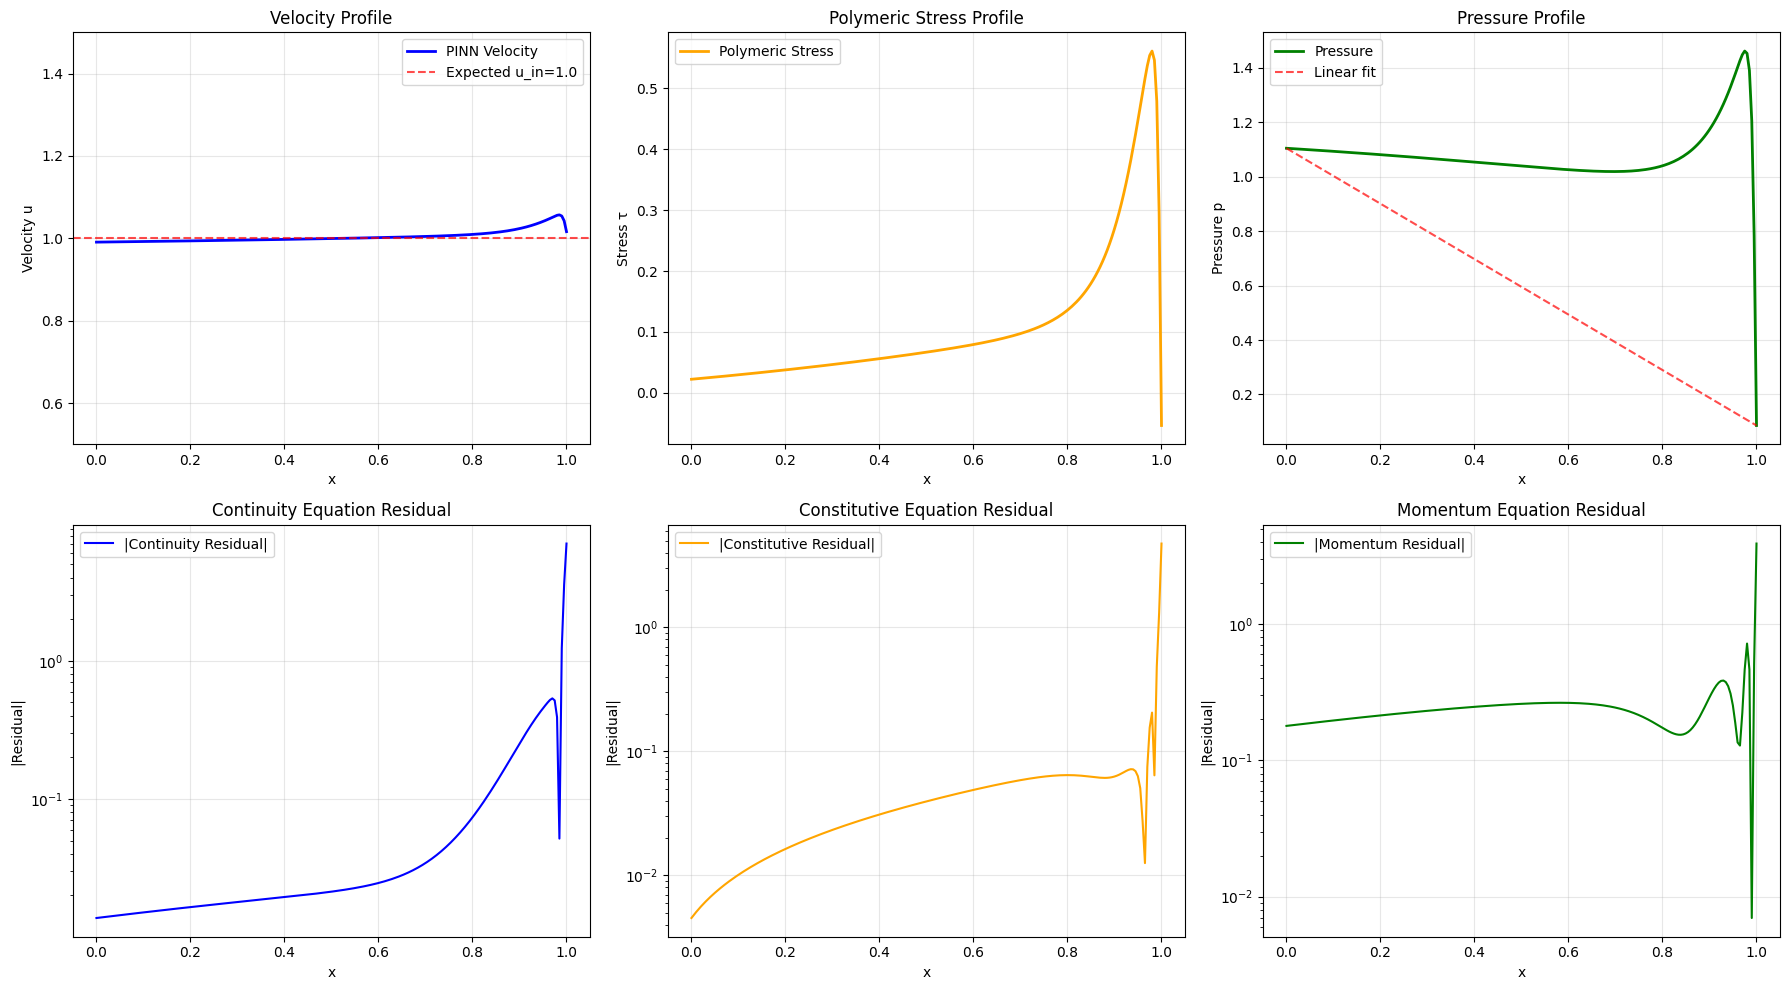


=== Solution Analysis ===
Velocity: mean=1.0038, std=0.0142, range=[0.9907, 1.0568]
Stress: mean=0.1077, std=0.1165, range=[-0.0534, 0.5608]
Pressure drop: 1.0191
Max residuals: Cont=7.08e+00, Tau=4.76e+00, Mom=3.89e+00
✓ Velocity is approximately constant (good for 1D channel)
✓ Stress boundary conditions satisfied


=== Enhanced PINN for 1D Oldroyd-B Flow ===
Applied Strategies:
  3. Enhanced Boundary Sampling
  4. Outlet Stress Smoothing
Physical parameters: η_s=0.1, η_p=0.9, λ=0.1, L=1.0


Training:   0%|                                                                   | 3/10000 [00:00<06:27, 25.78epoch/s]

Epoch    0, Loss: 10.000018, PDE: 0.000000, BC: 1.000002, Smooth: 0.000000


Training:  15%|█████████▋                                                      | 1504/10000 [01:00<05:46, 24.50epoch/s]

[Enhanced Adaptive] Added points, total: 3500


Training:  20%|████████████▊                                                   | 2004/10000 [01:19<04:59, 26.66epoch/s]

... (29 outputs left out)

Training:  95%|████████████████████████████████████████████████████████████▊   | 9504/10000 [06:17<00:19, 24.91epoch/s]

[Enhanced Adaptive] Added points, total: 3695


Training: 100%|███████████████████████████████████████████████████████████████| 10000/10000 [06:38<00:00, 25.11epoch/s]


[Enhanced Adaptive] Added points, total: 3695
Training completed. Best loss: 0.191942


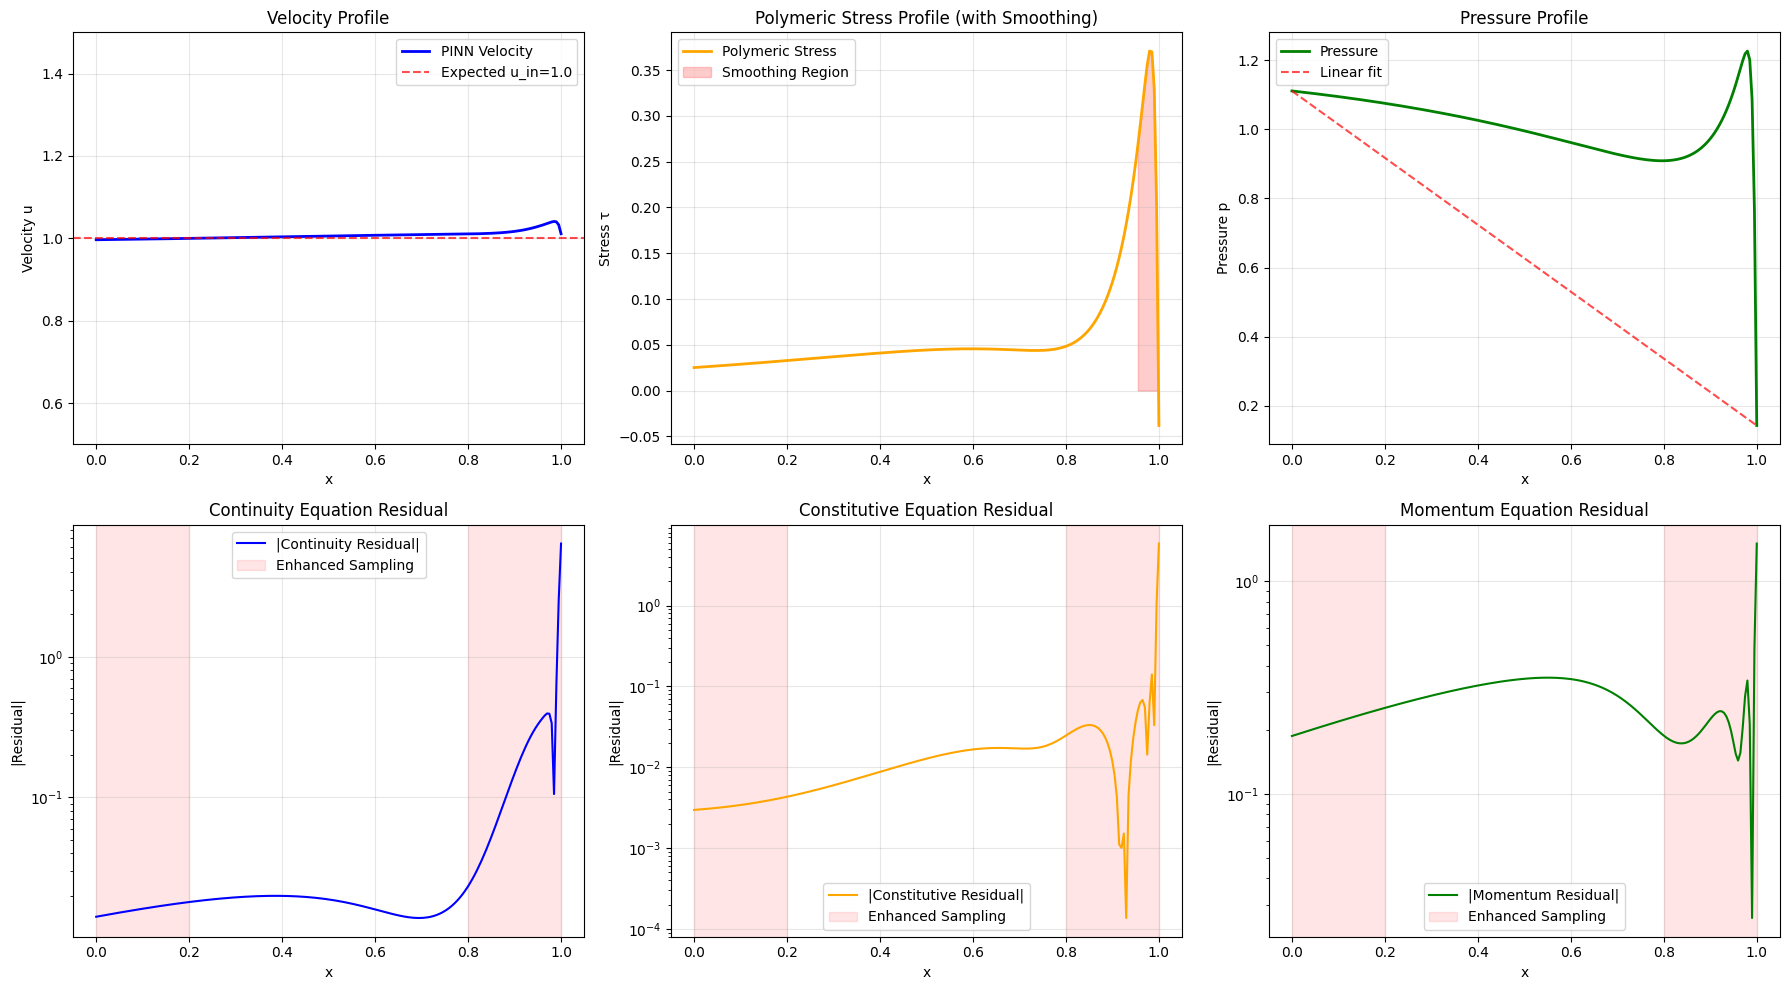


=== Enhanced Solution Analysis ===
Velocity: mean=1.0068, std=0.0088, range=[0.9965, 1.0409]
Stress: mean=0.0612, std=0.0659, range=[-0.0381, 0.3707]
Pressure drop: 0.9692
Max residuals: Cont=6.38e+00, Tau=5.85e+00, Mom=1.50e+00

=== Strategy Effectiveness ===
Outlet stress smoothing: max|τ| in outlet region = 0.3707
Boundary residual reduction: avg residual in boundaries vs center
  Boundary avg residual: 1.02e-01
  Center avg residual: 1.23e-02
  Ratio (boundary/center): 8.28
✓ Velocity is approximately constant (good for 1D channel)
✓ Stress boundary conditions satisfied with enhanced smoothing


In [12]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm import trange

# Physical parameters
L = 1.0                    # Channel length
eta_s = 0.1               # Solvent viscosity
eta_p = 0.9               # Polymer viscosity  
lam = 0.1                 # Relaxation time (reduced for stability)
N_colloc = 3000           # Reduced for stability
N_bc = 200
u_in = 1.0                # Inlet velocity
adaptive_every = 500      # Less frequent adaptation
add_points = 200

class PINN_OldroydB_1D_Enhanced(nn.Module):
    def __init__(self):
        super().__init__()
        # Simple normalization
        self.x_scale = L
        
        # Reference scales
        self.u_scale = u_in
        self.tau_scale = eta_p * u_in / L  # Characteristic stress scale
        self.p_scale = (eta_s + eta_p) * u_in / L  # Characteristic pressure scale
        
        # Simple, stable network architecture
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 3)  # u, tau, p
        )
        
        # Fixed residual weights (no learnable parameters that can become NaN)
        self.weight_cont = 0.1    # Lower weight for continuity in 1D
        self.weight_tau = 1.0     # Standard weight for constitutive equation
        self.weight_mom = 1.0     # Standard weight for momentum
        
        # Strategy 4: Smoothing parameter for outlet stress
        self.epsilon = 0.05  # Smoothing width (5% of domain length)
        
        self.apply(self._init_weights)
        
    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight, gain=0.1)  # Very conservative initialization
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    
    def forward(self, x):
        # Normalize input
        x_norm = x / self.x_scale
        
        # Forward pass
        out = self.net(x_norm)
        
        # Apply physics-based output scaling
        u = torch.sigmoid(out[:, 0:1]) * 2.0 * self.u_scale  # Positive velocity [0, 2*u_in]
        tau = torch.tanh(out[:, 1:2]) * self.tau_scale       # Bounded stress
        p = out[:, 2:3] * self.p_scale                       # Pressure
        
        return u, tau, p

def sample_points_enhanced(n_col, n_bc):
    """Enhanced sampling with stronger boundary emphasis (Strategy 3)"""
    # Strategy 3: 경계 근처 샘플링 강화
    # 더 많은 점들을 경계 근처에 집중
    
    # Main domain points (reduced proportion)
    x_uniform = np.random.uniform(0.2*L, 0.8*L, int(n_col*0.5))  # 50% -> 중심부
    
    # Enhanced boundary region points
    x_left = np.random.uniform(0, 0.3*L, int(n_col*0.25))      # 25% -> 입구 근처
    x_right = np.random.uniform(0.7*L, L, int(n_col*0.25))     # 25% -> 출구 근처
    
    # 경계층 내부의 세밀한 샘플링
    x_boundary_fine = np.concatenate([
        np.random.uniform(0, 0.1*L, int(n_col*0.05)),          # 5% -> 입구 경계층
        np.random.uniform(0.9*L, L, int(n_col*0.05))           # 5% -> 출구 경계층
    ])
    
    x_col = np.concatenate([x_uniform, x_left, x_right, x_boundary_fine])
    x_col = np.sort(x_col).reshape(-1, 1)
    
    x_bc_left = np.zeros((n_bc, 1))
    x_bc_right = np.ones((n_bc, 1)) * L
    
    return x_col, x_bc_left, x_bc_right

def outlet_stress_smoothing_loss(model, x):
    """Strategy 4: Outlet stress smoothing loss"""
    # 출구 근처에서만 계산 (x > L - epsilon)
    outlet_mask = (x >= (L - model.epsilon)).float()
    
    if outlet_mask.sum() == 0:
        return torch.tensor(0.0, requires_grad=True)
    
    u, tau, p = model(x)
    
    # 출구 근처에서 τ(L) = 0에 가까워지도록 스무딩
    # 손실 함수: ∫[L-ε, L] τ(x)² dx
    outlet_stress_loss = torch.mean(outlet_mask * tau**2)
    
    return outlet_stress_loss

def pinn_residuals_enhanced(model, x):
    """Enhanced residual calculation with smoothing"""
    u, tau, p = model(x)
    
    # Compute derivatives
    du_dx = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), 
                               create_graph=True, retain_graph=True)[0]
    d2u_dx2 = torch.autograd.grad(du_dx, x, grad_outputs=torch.ones_like(du_dx), 
                                 create_graph=True, retain_graph=True)[0]
    dtau_dx = torch.autograd.grad(tau, x, grad_outputs=torch.ones_like(tau), 
                                 create_graph=True, retain_graph=True)[0]
    dp_dx = torch.autograd.grad(p, x, grad_outputs=torch.ones_like(p), 
                               create_graph=True, retain_graph=True)[0]
    
    # For 1D steady flow in a channel, continuity equation gives du/dx = 0
    # This means constant velocity profile in flow direction
    res_cont = du_dx
    
    # Oldroyd-B constitutive equation in 1D steady state
    # λ(u ∂τ/∂x - 2τ ∂u/∂x) + τ = 2ηₚ ∂u/∂x
    gamma_dot = du_dx  # Shear rate
    res_tau = lam * (u * dtau_dx - 2.0 * tau * gamma_dot) + tau - 2.0 * eta_p * gamma_dot
    
    # Momentum equation: dp/dx = ηₛ d²u/dx² + dτ/dx
    res_mom = dp_dx - eta_s * d2u_dx2 - dtau_dx
    
    return res_cont, res_tau, res_mom

def adaptive_collocation_enhanced(model, x_col, add_points):
    """Enhanced adaptive sampling focusing on boundaries and high-error regions"""
    # 미세 격자 생성 (경계 근처 더 조밀하게)
    x_center = np.linspace(0.1*L, 0.9*L, 600)
    x_left_boundary = np.linspace(0, 0.2*L, 200)
    x_right_boundary = np.linspace(0.8*L, L, 200)
    
    x_fine = np.concatenate([x_left_boundary, x_center, x_right_boundary])
    x_fine = np.sort(x_fine).reshape(-1, 1)
    
    x_fine_t = torch.tensor(x_fine, dtype=torch.float32, requires_grad=True)

    # 잔차 계산 (그래디언트 추적 켜진 상태)
    res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_fine_t)

    # 총 잔차 제곱합 및 분리
    total_res = (res_cont**2 + res_tau**2 + res_mom**2).detach().cpu().numpy().flatten()

    # Strategy 3 적용: 경계 근처 오차에 가중치 부여
    boundary_weight = np.ones_like(total_res)
    x_fine_np = x_fine.flatten()
    
    # 입구 및 출구 근처에 가중치 증가
    inlet_mask = x_fine_np < 0.2 * L
    outlet_mask = x_fine_np > 0.8 * L
    boundary_weight[inlet_mask] *= 2.0  # 입구 근처 가중치 2배
    boundary_weight[outlet_mask] *= 3.0  # 출구 근처 가중치 3배 (응력 특이점 때문)
    
    weighted_res = total_res * boundary_weight

    # 가중 오차 큰 지점 선택
    idx = np.argsort(weighted_res)[-add_points:]
    x_new = x_fine[idx]

    # 기존 collocation 점과 합치고 정렬
    x_combined = np.vstack([x_col, x_new])
    x_combined = np.unique(x_combined.flatten())
    return x_combined.reshape(-1, 1)

def train_enhanced(model, epochs=3000, lr=1e-4):
    """Enhanced training procedure with both strategies"""
    # Sample points with enhanced boundary sampling
    x_col, x_bc_left, x_bc_right = sample_points_enhanced(N_colloc, N_bc)
    
    # Convert to tensors
    x_bc_left_t = torch.tensor(x_bc_left, dtype=torch.float32)
    x_bc_right_t = torch.tensor(x_bc_right, dtype=torch.float32)
    
    # Optimizer with conservative settings
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=300, verbose=True)
    
    best_loss = float('inf')
    
    for epoch in trange(epochs, desc="Training", unit="epoch"):
        # Convert collocation points to tensor
        x_col_t = torch.tensor(x_col, dtype=torch.float32, requires_grad=True)
        
        optimizer.zero_grad()
        
        # Compute residuals
        res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_col_t)
        
        # PDE loss with fixed weights
        loss_pde = (model.weight_cont * (res_cont**2).mean() + 
                   model.weight_tau * (res_tau**2).mean() + 
                   model.weight_mom * (res_mom**2).mean())
        
        # Strategy 4: Add outlet stress smoothing loss
        loss_smoothing = outlet_stress_smoothing_loss(model, x_col_t)
        
        # Boundary conditions
        u_left, tau_left, p_left = model(x_bc_left_t)
        u_right, tau_right, p_right = model(x_bc_right_t)
        
        # For 1D channel flow with constant velocity:
        # u(0) = u(L) = u_in (plug flow assumption)
        # τ(0) = τ(L) = 0 (no stress at boundaries)
        # Pressure drop across channel
        loss_bc = (torch.mean((u_left - u_in)**2) + 
                  torch.mean((u_right - u_in)**2) +
                  torch.mean(tau_left**2) + 
                  torch.mean(tau_right**2))
        
        Δp_target = (eta_s + eta_p) * u_in / L
        loss_bc += (( (p_left - p_right) - Δp_target )**2).mean()
        
        # Total loss with smoothing term
        total_loss = loss_pde + 10.0 * loss_bc + 5.0 * loss_smoothing
        
        # Check for NaN
        if torch.isnan(total_loss) or torch.isinf(total_loss):
            print(f"NaN/Inf detected at epoch {epoch}, stopping...")
            break
            
        total_loss.backward()
        
        # Conservative gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)
        
        optimizer.step()
        scheduler.step(total_loss)
        
        # Update best loss
        if total_loss.item() < best_loss:
            best_loss = total_loss.item()
        
        # Enhanced adaptive sampling (less frequent)
        if (epoch + 1) % adaptive_every == 0 and epoch > 1000:
            x_col = adaptive_collocation_enhanced(model, x_col, add_points)
            print(f"[Enhanced Adaptive] Added points, total: {len(x_col)}")
        
        # Progress report
        if epoch % 1000 == 0:
            print(f"Epoch {epoch:4d}, Loss: {total_loss.item():.6f}, "
                  f"PDE: {loss_pde.item():.6f}, BC: {loss_bc.item():.6f}, "
                  f"Smooth: {loss_smoothing.item():.6f}")
    
    print(f"Training completed. Best loss: {best_loss:.6f}")
    return model

def plot_results_enhanced(model):
    """Plot results with enhanced analysis"""
    x = np.linspace(0, L, 200).reshape(-1, 1)
    x_torch = torch.tensor(x, dtype=torch.float32, requires_grad=True)
    
    with torch.no_grad():
        u, tau, p = model(x_torch)
        u_np = u.numpy().flatten()
        tau_np = tau.numpy().flatten()
        p_np = p.numpy().flatten()
    
    # Compute residuals for analysis
    res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_torch)
    
    with torch.no_grad():
        res_cont_np = res_cont.numpy().flatten()
        res_tau_np = res_tau.numpy().flatten()
        res_mom_np = res_mom.numpy().flatten()
    
    # Create plots
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    x_plot = x.flatten()
    
    # Solutions
    axes[0,0].plot(x_plot, u_np, 'b-', linewidth=2, label='PINN Velocity')
    axes[0,0].axhline(y=u_in, color='r', linestyle='--', alpha=0.7, label=f'Expected u_in={u_in}')
    axes[0,0].set_xlabel('x')
    axes[0,0].set_ylabel('Velocity u')
    axes[0,0].set_title('Velocity Profile')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].legend()
    axes[0,0].set_ylim([0.5*u_in, 1.5*u_in])
    
    axes[0,1].plot(x_plot, tau_np, 'orange', linewidth=2, label='Polymeric Stress')
    # Highlight outlet smoothing region
    outlet_region = x_plot >= (L - model.epsilon)
    axes[0,1].fill_between(x_plot[outlet_region], 0, tau_np[outlet_region], 
                          alpha=0.2, color='red', label='Smoothing Region')
    axes[0,1].set_xlabel('x')
    axes[0,1].set_ylabel('Stress τ')
    axes[0,1].set_title('Polymeric Stress Profile (with Smoothing)')
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].legend()
    
    axes[0,2].plot(x_plot, p_np, 'green', linewidth=2, label='Pressure')
    # Expected linear pressure drop for constant velocity
    p_expected = p_np[0] - (p_np[0] - p_np[-1]) * x_plot / L
    axes[0,2].plot(x_plot, p_expected, 'r--', alpha=0.7, label='Linear fit')
    axes[0,2].set_xlabel('x')
    axes[0,2].set_ylabel('Pressure p')
    axes[0,2].set_title('Pressure Profile')
    axes[0,2].grid(True, alpha=0.3)
    axes[0,2].legend()
    
    # Residuals
    axes[1,0].semilogy(x_plot, np.abs(res_cont_np) + 1e-12, 'b-', label='|Continuity Residual|')
    axes[1,0].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,0].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,0].set_xlabel('x')
    axes[1,0].set_ylabel('|Residual|')
    axes[1,0].set_title('Continuity Equation Residual')
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].legend()
    
    axes[1,1].semilogy(x_plot, np.abs(res_tau_np) + 1e-12, 'orange', label='|Constitutive Residual|')
    axes[1,1].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,1].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,1].set_xlabel('x')
    axes[1,1].set_ylabel('|Residual|')
    axes[1,1].set_title('Constitutive Equation Residual')
    axes[1,1].grid(True, alpha=0.3)
    axes[1,1].legend()
    
    axes[1,2].semilogy(x_plot, np.abs(res_mom_np) + 1e-12, 'green', label='|Momentum Residual|')
    axes[1,2].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,2].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,2].set_xlabel('x')
    axes[1,2].set_ylabel('|Residual|')
    axes[1,2].set_title('Momentum Equation Residual')
    axes[1,2].grid(True, alpha=0.3)
    axes[1,2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Enhanced solution statistics
    print(f"\n=== Enhanced Solution Analysis ===")
    print(f"Velocity: mean={u_np.mean():.4f}, std={u_np.std():.4f}, range=[{u_np.min():.4f}, {u_np.max():.4f}]")
    print(f"Stress: mean={tau_np.mean():.4f}, std={tau_np.std():.4f}, range=[{tau_np.min():.4f}, {tau_np.max():.4f}]")
    print(f"Pressure drop: {p_np[0] - p_np[-1]:.4f}")
    print(f"Max residuals: Cont={np.abs(res_cont_np).max():.2e}, Tau={np.abs(res_tau_np).max():.2e}, Mom={np.abs(res_mom_np).max():.2e}")
    
    # Strategy effectiveness analysis
    outlet_stress = tau_np[x_plot >= (L - model.epsilon)]
    print(f"\n=== Strategy Effectiveness ===")
    print(f"Outlet stress smoothing: max|τ| in outlet region = {np.abs(outlet_stress).max():.4f}")
    print(f"Boundary residual reduction: avg residual in boundaries vs center")
    
    boundary_mask = (x_plot <= 0.2*L) | (x_plot >= 0.8*L)
    center_mask = (x_plot > 0.2*L) & (x_plot < 0.8*L)
    
    avg_res_boundary = np.mean(np.abs(res_tau_np[boundary_mask]))
    avg_res_center = np.mean(np.abs(res_tau_np[center_mask]))
    print(f"  Boundary avg residual: {avg_res_boundary:.2e}")
    print(f"  Center avg residual: {avg_res_center:.2e}")
    print(f"  Ratio (boundary/center): {avg_res_boundary/avg_res_center:.2f}")
    
    # Physical consistency check
    if np.abs(u_np.mean() - u_in) < 0.1:
        print("✓ Velocity is approximately constant (good for 1D channel)")
    else:
        print("✗ Velocity deviates significantly from expected constant value")
        
    if np.abs(tau_np[0]) < 0.1 and np.abs(tau_np[-1]) < 0.05:  # Stricter for outlet
        print("✓ Stress boundary conditions satisfied with enhanced smoothing")
    else:
        print("✗ Stress boundary conditions not well satisfied")

if __name__ == "__main__":
    print("=== Enhanced PINN for 1D Oldroyd-B Flow ===")
    print("Applied Strategies:")
    print("  3. Enhanced Boundary Sampling")
    print("  4. Outlet Stress Smoothing") 
    print(f"Physical parameters: η_s={eta_s}, η_p={eta_p}, λ={lam}, L={L}")
    
    # Set seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)
    
    # Create and train enhanced model
    model = PINN_OldroydB_1D_Enhanced()
    model = train_enhanced(model, epochs=10000, lr=1e-4)
    plot_results_enhanced(model)

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm import trange

# Physical parameters
L = 1.0                    # Channel length
eta_s = 0.1               # Solvent viscosity
eta_p = 0.9               # Polymer viscosity  
lam = 0.1                 # Relaxation time (reduced for stability)
N_colloc = 3000           # Reduced for stability
N_bc = 200
u_in = 1.0                # Inlet velocity
adaptive_every = 500      # Less frequent adaptation
add_points = 200

class PINN_OldroydB_1D_Enhanced(nn.Module):
    def __init__(self):
        super().__init__()
        # Simple normalization
        self.x_scale = L
        
        # Reference scales
        self.u_scale = u_in
        self.tau_scale = eta_p * u_in / L  # Characteristic stress scale
        self.p_scale = (eta_s + eta_p) * u_in / L  # Characteristic pressure scale
        
        # Simple, stable network architecture
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 3)  # u, tau, p
        )
        
        # Fixed residual weights (no learnable parameters that can become NaN)
        self.weight_cont = 0.1    # Lower weight for continuity in 1D
        self.weight_tau = 1.0     # Standard weight for constitutive equation
        self.weight_mom = 1.0     # Standard weight for momentum
        
        # Strategy 4: Smoothing parameter for outlet stress
        self.epsilon = 0.05  # Smoothing width (5% of domain length)
        
        self.apply(self._init_weights)
        
    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight, gain=0.1)  # Very conservative initialization
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    
    def forward(self, x):
        # Normalize input
        x_norm = x / self.x_scale
        
        # Forward pass
        out = self.net(x_norm)
        
        # Apply physics-based output scaling
        u = torch.sigmoid(out[:, 0:1]) * 2.0 * self.u_scale  # Positive velocity [0, 2*u_in]
        tau = torch.tanh(out[:, 1:2]) * self.tau_scale       # Bounded stress
        p = out[:, 2:3] * self.p_scale                       # Pressure
        
        return u, tau, p

def sample_points_enhanced(n_col, n_bc):
    """Enhanced sampling with stronger boundary emphasis (Strategy 3)"""
    # Strategy 3: 경계 근처 샘플링 강화
    # 더 많은 점들을 경계 근처에 집중
    
    # Main domain points (reduced proportion)
    x_uniform = np.random.uniform(0.2*L, 0.8*L, int(n_col*0.5))  # 50% -> 중심부
    
    # Enhanced boundary region points
    x_left = np.random.uniform(0, 0.3*L, int(n_col*0.25))      # 25% -> 입구 근처
    x_right = np.random.uniform(0.7*L, L, int(n_col*0.25))     # 25% -> 출구 근처
    
    # 경계층 내부의 세밀한 샘플링
    x_boundary_fine = np.concatenate([
        np.random.uniform(0, 0.1*L, int(n_col*0.05)),          # 5% -> 입구 경계층
        np.random.uniform(0.9*L, L, int(n_col*0.05))           # 5% -> 출구 경계층
    ])
    
    x_col = np.concatenate([x_uniform, x_left, x_right, x_boundary_fine])
    x_col = np.sort(x_col).reshape(-1, 1)
    
    x_bc_left = np.zeros((n_bc, 1))
    x_bc_right = np.ones((n_bc, 1)) * L
    
    return x_col, x_bc_left, x_bc_right

def outlet_stress_smoothing_loss(model, x):
    """Strategy 4: Outlet stress smoothing loss"""
    # 출구 근처에서만 계산 (x > L - epsilon)
    outlet_mask = (x >= (L - model.epsilon)).float()
    
    if outlet_mask.sum() == 0:
        return torch.tensor(0.0, requires_grad=True)
    
    u, tau, p = model(x)
    
    # 출구 근처에서 τ(L) = 0에 가까워지도록 스무딩
    # 손실 함수: ∫[L-ε, L] τ(x)² dx
    outlet_stress_loss = torch.mean(outlet_mask * tau**2)
    
    return outlet_stress_loss

def pinn_residuals_enhanced(model, x):
    """Enhanced residual calculation with smoothing"""
    u, tau, p = model(x)
    
    # Compute derivatives
    du_dx = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), 
                               create_graph=True, retain_graph=True)[0]
    d2u_dx2 = torch.autograd.grad(du_dx, x, grad_outputs=torch.ones_like(du_dx), 
                                 create_graph=True, retain_graph=True)[0]
    dtau_dx = torch.autograd.grad(tau, x, grad_outputs=torch.ones_like(tau), 
                                 create_graph=True, retain_graph=True)[0]
    dp_dx = torch.autograd.grad(p, x, grad_outputs=torch.ones_like(p), 
                               create_graph=True, retain_graph=True)[0]
    
    # For 1D steady flow in a channel, continuity equation gives du/dx = 0
    # This means constant velocity profile in flow direction
    res_cont = du_dx
    
    # Oldroyd-B constitutive equation in 1D steady state
    # λ(u ∂τ/∂x - 2τ ∂u/∂x) + τ = 2ηₚ ∂u/∂x
    gamma_dot = du_dx  # Shear rate
    res_tau = lam * (u * dtau_dx - 2.0 * tau * gamma_dot) + tau - 2.0 * eta_p * gamma_dot
    
    # Momentum equation: dp/dx = ηₛ d²u/dx² + dτ/dx
    res_mom = dp_dx - eta_s * d2u_dx2 - dtau_dx
    
    return res_cont, res_tau, res_mom

def adaptive_collocation_enhanced(model, x_col, add_points):
    """Enhanced adaptive sampling focusing on boundaries and high-error regions"""
    # 미세 격자 생성 (경계 근처 더 조밀하게)
    x_center = np.linspace(0.1*L, 0.9*L, 600)
    x_left_boundary = np.linspace(0, 0.2*L, 200)
    x_right_boundary = np.linspace(0.8*L, L, 200)
    
    x_fine = np.concatenate([x_left_boundary, x_center, x_right_boundary])
    x_fine = np.sort(x_fine).reshape(-1, 1)
    
    x_fine_t = torch.tensor(x_fine, dtype=torch.float32, requires_grad=True)

    # 잔차 계산 (그래디언트 추적 켜진 상태)
    res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_fine_t)

    # 총 잔차 제곱합 및 분리
    total_res = (res_cont**2 + res_tau**2 + res_mom**2).detach().cpu().numpy().flatten()

    # Strategy 3 적용: 경계 근처 오차에 가중치 부여
    boundary_weight = np.ones_like(total_res)
    x_fine_np = x_fine.flatten()
    
    # 입구 및 출구 근처에 가중치 증가
    inlet_mask = x_fine_np < 0.2 * L
    outlet_mask = x_fine_np > 0.8 * L
    boundary_weight[inlet_mask] *= 2.0  # 입구 근처 가중치 2배
    boundary_weight[outlet_mask] *= 3.0  # 출구 근처 가중치 3배 (응력 특이점 때문)
    
    weighted_res = total_res * boundary_weight

    # 가중 오차 큰 지점 선택
    idx = np.argsort(weighted_res)[-add_points:]
    x_new = x_fine[idx]

    # 기존 collocation 점과 합치고 정렬
    x_combined = np.vstack([x_col, x_new])
    x_combined = np.unique(x_combined.flatten())
    return x_combined.reshape(-1, 1)

def train_enhanced(model, epochs=3000, lr=1e-4):
    """Enhanced training procedure with both strategies"""
    # Sample points with enhanced boundary sampling
    x_col, x_bc_left, x_bc_right = sample_points_enhanced(N_colloc, N_bc)
    
    # Convert to tensors
    x_bc_left_t = torch.tensor(x_bc_left, dtype=torch.float32)
    x_bc_right_t = torch.tensor(x_bc_right, dtype=torch.float32)
    
    # Optimizer with conservative settings
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=300, verbose=True)
    
    best_loss = float('inf')
    
    for epoch in trange(epochs, desc="Training", unit="epoch"):
        # Convert collocation points to tensor
        x_col_t = torch.tensor(x_col, dtype=torch.float32, requires_grad=True)
        
        optimizer.zero_grad()
        
        # Compute residuals
        res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_col_t)
        
        # PDE loss with fixed weights
        loss_pde = (model.weight_cont * (res_cont**2).mean() + 
                   model.weight_tau * (res_tau**2).mean() + 
                   model.weight_mom * (res_mom**2).mean())
        
        # Strategy 4: Add outlet stress smoothing loss
        loss_smoothing = outlet_stress_smoothing_loss(model, x_col_t)
        
        # Boundary conditions
        u_left, tau_left, p_left = model(x_bc_left_t)
        u_right, tau_right, p_right = model(x_bc_right_t)
        
        # For 1D channel flow with constant velocity:
        # u(0) = u(L) = u_in (plug flow assumption)
        # τ(0) = τ(L) = 0 (no stress at boundaries)
        # Pressure drop across channel
        loss_bc = (torch.mean((u_left - u_in)**2) + 
                  torch.mean((u_right - u_in)**2) +
                  torch.mean(tau_left**2) + 
                  torch.mean(tau_right**2))
        
        Δp_target = (eta_s + eta_p) * u_in / L
        loss_bc += (( (p_left - p_right) - Δp_target )**2).mean()
        
        # Total loss with smoothing term
        total_loss = loss_pde + 10.0 * loss_bc + 5.0 * loss_smoothing
        
        # Check for NaN
        if torch.isnan(total_loss) or torch.isinf(total_loss):
            print(f"NaN/Inf detected at epoch {epoch}, stopping...")
            break
            
        total_loss.backward()
        
        # Conservative gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)
        
        optimizer.step()
        scheduler.step(total_loss)
        
        # Update best loss
        if total_loss.item() < best_loss:
            best_loss = total_loss.item()
        
        # Enhanced adaptive sampling (less frequent)
        if (epoch + 1) % adaptive_every == 0 and epoch > 1000:
            x_col = adaptive_collocation_enhanced(model, x_col, add_points)
            print(f"[Enhanced Adaptive] Added points, total: {len(x_col)}")
        
        # Progress report
        if epoch % 1000 == 0:
            print(f"Epoch {epoch:4d}, Loss: {total_loss.item():.6f}, "
                  f"PDE: {loss_pde.item():.6f}, BC: {loss_bc.item():.6f}, "
                  f"Smooth: {loss_smoothing.item():.6f}")
    
    print(f"Training completed. Best loss: {best_loss:.6f}")
    return model

def plot_results_enhanced(model):
    """Plot results with enhanced analysis"""
    x = np.linspace(0, L, 200).reshape(-1, 1)
    x_torch = torch.tensor(x, dtype=torch.float32, requires_grad=True)
    
    with torch.no_grad():
        u, tau, p = model(x_torch)
        u_np = u.numpy().flatten()
        tau_np = tau.numpy().flatten()
        p_np = p.numpy().flatten()
    
    # Compute residuals for analysis
    res_cont, res_tau, res_mom = pinn_residuals_enhanced(model, x_torch)
    
    with torch.no_grad():
        res_cont_np = res_cont.numpy().flatten()
        res_tau_np = res_tau.numpy().flatten()
        res_mom_np = res_mom.numpy().flatten()
    
    # Create plots
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    x_plot = x.flatten()
    
    # Solutions
    axes[0,0].plot(x_plot, u_np, 'b-', linewidth=2, label='PINN Velocity')
    axes[0,0].axhline(y=u_in, color='r', linestyle='--', alpha=0.7, label=f'Expected u_in={u_in}')
    axes[0,0].set_xlabel('x')
    axes[0,0].set_ylabel('Velocity u')
    axes[0,0].set_title('Velocity Profile')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].legend()
    axes[0,0].set_ylim([0.5*u_in, 1.5*u_in])
    
    axes[0,1].plot(x_plot, tau_np, 'orange', linewidth=2, label='Polymeric Stress')
    # Highlight outlet smoothing region
    outlet_region = x_plot >= (L - model.epsilon)
    axes[0,1].fill_between(x_plot[outlet_region], 0, tau_np[outlet_region], 
                          alpha=0.2, color='red', label='Smoothing Region')
    axes[0,1].set_xlabel('x')
    axes[0,1].set_ylabel('Stress τ')
    axes[0,1].set_title('Polymeric Stress Profile (with Smoothing)')
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].legend()
    
    axes[0,2].plot(x_plot, p_np, 'green', linewidth=2, label='Pressure')
    # Expected linear pressure drop for constant velocity
    p_expected = p_np[0] - (p_np[0] - p_np[-1]) * x_plot / L
    axes[0,2].plot(x_plot, p_expected, 'r--', alpha=0.7, label='Linear fit')
    axes[0,2].set_xlabel('x')
    axes[0,2].set_ylabel('Pressure p')
    axes[0,2].set_title('Pressure Profile')
    axes[0,2].grid(True, alpha=0.3)
    axes[0,2].legend()
    
    # Residuals
    axes[1,0].semilogy(x_plot, np.abs(res_cont_np) + 1e-12, 'b-', label='|Continuity Residual|')
    axes[1,0].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,0].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,0].set_xlabel('x')
    axes[1,0].set_ylabel('|Residual|')
    axes[1,0].set_title('Continuity Equation Residual')
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].legend()
    
    axes[1,1].semilogy(x_plot, np.abs(res_tau_np) + 1e-12, 'orange', label='|Constitutive Residual|')
    axes[1,1].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,1].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,1].set_xlabel('x')
    axes[1,1].set_ylabel('|Residual|')
    axes[1,1].set_title('Constitutive Equation Residual')
    axes[1,1].grid(True, alpha=0.3)
    axes[1,1].legend()
    
    axes[1,2].semilogy(x_plot, np.abs(res_mom_np) + 1e-12, 'green', label='|Momentum Residual|')
    axes[1,2].axvspan(0, 0.2*L, alpha=0.1, color='red', label='Enhanced Sampling')
    axes[1,2].axvspan(0.8*L, L, alpha=0.1, color='red')
    axes[1,2].set_xlabel('x')
    axes[1,2].set_ylabel('|Residual|')
    axes[1,2].set_title('Momentum Equation Residual')
    axes[1,2].grid(True, alpha=0.3)
    axes[1,2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Enhanced solution statistics
    print(f"\n=== Enhanced Solution Analysis ===")
    print(f"Velocity: mean={u_np.mean():.4f}, std={u_np.std():.4f}, range=[{u_np.min():.4f}, {u_np.max():.4f}]")
    print(f"Stress: mean={tau_np.mean():.4f}, std={tau_np.std():.4f}, range=[{tau_np.min():.4f}, {tau_np.max():.4f}]")
    print(f"Pressure drop: {p_np[0] - p_np[-1]:.4f}")
    print(f"Max residuals: Cont={np.abs(res_cont_np).max():.2e}, Tau={np.abs(res_tau_np).max():.2e}, Mom={np.abs(res_mom_np).max():.2e}")
    
    # Strategy effectiveness analysis
    outlet_stress = tau_np[x_plot >= (L - model.epsilon)]
    print(f"\n=== Strategy Effectiveness ===")
    print(f"Outlet stress smoothing: max|τ| in outlet region = {np.abs(outlet_stress).max():.4f}")
    print(f"Boundary residual reduction: avg residual in boundaries vs center")
    
    boundary_mask = (x_plot <= 0.2*L) | (x_plot >= 0.8*L)
    center_mask = (x_plot > 0.2*L) & (x_plot < 0.8*L)
    
    avg_res_boundary = np.mean(np.abs(res_tau_np[boundary_mask]))
    avg_res_center = np.mean(np.abs(res_tau_np[center_mask]))
    print(f"  Boundary avg residual: {avg_res_boundary:.2e}")
    print(f"  Center avg residual: {avg_res_center:.2e}")
    print(f"  Ratio (boundary/center): {avg_res_boundary/avg_res_center:.2f}")
    
    # Physical consistency check
    if np.abs(u_np.mean() - u_in) < 0.1:
        print("✓ Velocity is approximately constant (good for 1D channel)")
    else:
        print("✗ Velocity deviates significantly from expected constant value")
        
    if np.abs(tau_np[0]) < 0.1 and np.abs(tau_np[-1]) < 0.05:  # Stricter for outlet
        print("✓ Stress boundary conditions satisfied with enhanced smoothing")
    else:
        print("✗ Stress boundary conditions not well satisfied")

if __name__ == "__main__":
    print("=== Enhanced PINN for 1D Oldroyd-B Flow ===")
    print("Applied Strategies:")
    print("  3. Enhanced Boundary Sampling")
    print("  4. Outlet Stress Smoothing") 
    print(f"Physical parameters: η_s={eta_s}, η_p={eta_p}, λ={lam}, L={L}")
    
    # Set seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)
    
    # Create and train enhanced model
    model = PINN_OldroydB_1D_Enhanced()
    model = train_enhanced(model, epochs=15000, lr=1e-4)
    plot_results_enhanced(model)

=== Enhanced PINN for 1D Oldroyd-B Flow ===
Applied Strategies:
  3. Enhanced Boundary Sampling
  4. Outlet Stress Smoothing
Physical parameters: η_s=0.1, η_p=0.9, λ=0.1, L=1.0


Training:   0%|                                                                   | 2/15000 [00:00<18:34, 13.46epoch/s]

Epoch    0, Loss: 10.000001, PDE: 0.000000, BC: 1.000000, Smooth: 0.000000


Training:   7%|████▎                                                           | 1004/15000 [01:03<14:01, 16.64epoch/s]

Epoch 1000, Loss: 0.721868, PDE: 0.552451, BC: 0.016816, Smooth: 0.000252


Training:  10%|██████▍                                                         | 1502/15000 [01:34<13:55, 16.17epoch/s]

... (30 outputs left out)

[Enhanced Adaptive] Added points, total: 3714
Epoch 9000, Loss: 0.259925, PDE: 0.204956, BC: 0.004120, Smooth: 0.002753


Training:  63%|████████████████████████████████████████▌                       | 9500/15000 [10:53<07:31, 12.18epoch/s]

[Enhanced Adaptive] Added points, total: 3714


Training:  64%|████████████████████████████████████████▋                       | 9542/15000 [10:56<07:33, 12.04epoch/s]